In [ ]:
import numpy as np

# =============================================================================
# 1. CONFIGURACIÓN DE PARÁMETROS Y REPRODUCIBILIDAD
# =============================================================================
np.random.seed(42)  # Semilla aleatoria fija para asegurar reproducibilidad

N = 300  # Número total de observaciones
P = 5    # Número de características originales
Q = 20   # Número total de características transformadas

sigma_eta = 0.5
sigma_eta_sq = sigma_eta**2  # Varianza del ruido: 0.25
lambda_reg = 1.0             # Hiperparámetro de regularización Ridge

# Prior gaussiano compatible: lambda = sigma_eta^2 / sigma_w^2 => sigma_w^2 = sigma_eta^2 / lambda
sigma_w_sq = sigma_eta_sq / lambda_reg  # sigma_w^2 = 0.25 / 1.0 = 0.25

# =============================================================================
# 2. GENERACIÓN DE LA MATRIZ DE ENTRADA X
# =============================================================================
# Filas de X ~ N(0, I_P) i.i.d.
X = np.random.randn(N, P)  # Forma: (300, 5)

# =============================================================================
# 3. CONSTRUCCIÓN REPRODUCIBLE DE Phi(X) IN R^(N x Q)
# =============================================================================
# Orden de las Q = 20 características:
# 1. Primeras 5 columnas: términos lineales x_1, ..., x_5
# 2. Siguientes 5 columnas: términos cuadráticos x_1^2, ..., x_5^2
# 3. Últimas 10 columnas: interacciones por pares x_i * x_j (i < j)

phi_cols = []

# (a) 5 columnas originales (lineales)
for i in range(P):
    phi_cols.append(X[:, i : i + 1])

# (b) 5 columnas cuadráticas
for i in range(P):
    phi_cols.append(X[:, i : i + 1] ** 2)

# (c) 10 productos cruzados por pares
for i in range(P):
    for j in range(i + 1, P):
        phi_cols.append(X[:, i : i + 1] * X[:, j : j + 1])

Phi = np.hstack(phi_cols)  # Dimensión resultante: (300, 20)

# Verificar rango completo por columnas
rank_phi = np.linalg.matrix_rank(Phi)
print(f"Rango de la Matriz de Diseño Phi: {rank_phi} / {Q}")

# =============================================================================
# 4. GENERACIÓN DE w_* Y VECTOR DE RESPUESTAS t
# =============================================================================
w_true = np.random.randn(Q, 1)                       # w_* ~ N(0, I_Q)
eta = np.random.normal(0, sigma_eta, size=(N, 1))    # Ruido eta ~ N(0, 0.5^2)
t = Phi @ w_true + eta                               # t = Phi * w_* + eta

# =============================================================================
# 5. PARTICIÓN ALEATORIA: ENTRENAMIENTO (80%) / PRUEBA (20%)
# =============================================================================
indices = np.random.permutation(N)
N_train = int(0.8 * N)  # 240 datos de entrenamiento, 60 datos de prueba
train_idx, test_idx = indices[:N_train], indices[N_train:]

Phi_train, t_train = Phi[train_idx], t[train_idx]
Phi_test, t_test = Phi[test_idx], t[test_idx]

# =============================================================================
# 6. AJUSTE DE LOS CUATRO ESTIMADORES
# =============================================================================
I_Q = np.eye(Q)
A = Phi_train.T @ Phi_train
b = Phi_train.T @ t_train

# 1. Mínimos Cuadrados Ordinarios (OLS) mediante inversión explícita
w_ols = np.linalg.inv(A) @ b

# 2. Máxima Verosimilitud (MLE) mediante resolución de sistema lineal
w_mle = np.linalg.solve(A, b)

# 3. Regularización Cuadrática (Ridge) con lambda = 1.0
w_ridge = np.linalg.solve(A + lambda_reg * I_Q, b)

# 4. Máximo a Posteriori (MAP) con ratio lambda_MAP = sigma_eta^2 / sigma_w^2
lambda_map = sigma_eta_sq / sigma_w_sq
w_map = np.linalg.solve(A + lambda_map * I_Q, b)

# =============================================================================
# 7. EVALUACIÓN Y REPORTE DE RESULTADOS
# =============================================================================
def evaluate_model(w_est):
    pred_train = Phi_train @ w_est
    pred_test = Phi_test @ w_est

    mse_train = np.mean((t_train - pred_train) ** 2)
    mse_test = np.mean((t_test - pred_test) ** 2)
    norm_diff = np.linalg.norm(w_est - w_true)

    return mse_train, mse_test, norm_diff

models = {
    "OLS (Mínimos Cuadrados)": w_ols,
    "MLE (Máxima Verosimilitud)": w_mle,
    "Ridge (Regularización L2)": w_ridge,
    "MAP (Máximo a Posteriori)": w_map
}

print("\n" + "=" * 75)
print(f"{'Estimador':<30} | {'MSE Train':<10} | {'MSE Test':<10} | {'||w_hat - w*||_2':<15}")
print("=" * 75)
for name, w_est in models.items():
    mse_tr, mse_te, diff = evaluate_model(w_est)
    print(f"{name:<30} | {mse_tr:<10.5f} | {mse_te:<10.5f} | {diff:<15.5f}")
print("=" * 75)

# Verificación directa de discrepancias numéricas
print("\n--- Verificación de Coincidencias Numéricas ---")
diff_ols_mle = np.linalg.norm(w_ols - w_mle)
diff_ridge_map = np.linalg.norm(w_ridge - w_map)
print(f"Norma de la diferencia ||w_OLS - w_MLE||:   {diff_ols_mle:.2e}")
print(f"Norma de la diferencia ||w_Ridge - w_MAP||: {diff_ridge_map:.2e}")

Rango de la Matriz de Diseño Phi: 20 / 20

Estimador                      | MSE Train  | MSE Test   | ||w_hat - w*||_2
OLS (Mínimos Cuadrados)        | 0.22558    | 0.25294    | 0.15481        
MLE (Máxima Verosimilitud)     | 0.22558    | 0.25294    | 0.15481        
Ridge (Regularización L2)      | 0.22588    | 0.25137    | 0.14608        
MAP (Máximo a Posteriori)      | 0.22588    | 0.25137    | 0.14608        

--- Verificación de Coincidencias Numéricas ---
Norma de la diferencia ||w_OLS - w_MLE||:   1.79e-15
Norma de la diferencia ||w_Ridge - w_MAP||: 0.00e+00


Cargando datasets MNIST y Fashion-MNIST...
Ancho de banda obtenido (Mediana): sigma = 11.01


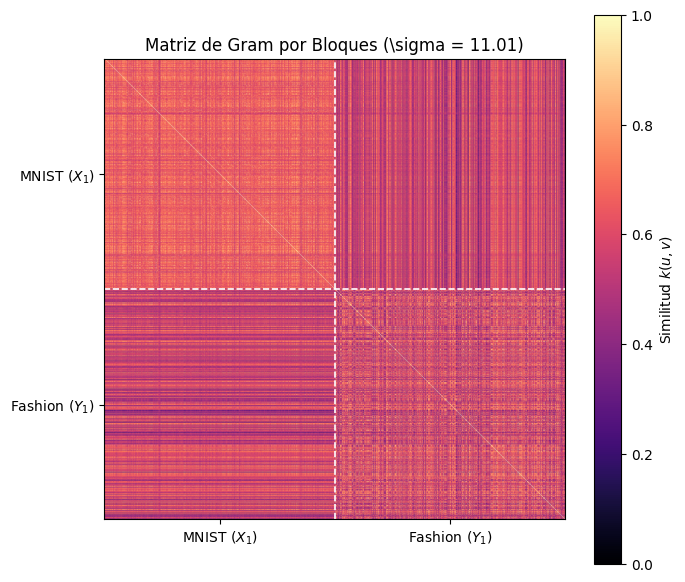

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist, pdist
from sklearn.datasets import fetch_openml

# Fijar semilla aleatoria para garantizar que los resultados y particiones sean reproducibles
np.random.seed(42)

# =====================================================================
# 1. CARGA, PARTICIONAMIENTO Y PREPROCESAMIENTO DE DATOS
# =====================================================================
print("Cargando datasets MNIST y Fashion-MNIST...")
try:
    # Intentar descargar los datasets MNIST y Fashion-MNIST originales desde OpenML
    mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
    fashion = fetch_openml('Fashion-MNIST', version=1, as_frame=False, parser='auto')

    # Seleccionar las primeras 1000 imágenes de cada dataset para el análisis
    X_raw = mnist.data[:1000].astype(np.float32)
    Y_raw = fashion.data[:1000].astype(np.float32)
except Exception:
    # En caso de fallo de red o servidor no disponible, se generan datos sintéticos con distribuciones distintas
    print("Servidor no disponible. Generando muestras sintéticas de prueba...")
    X_raw = np.random.normal(loc=100, scale=30, size=(1000, 784)).clip(0, 255)
    Y_raw = np.random.normal(loc=160, scale=40, size=(1000, 784)).clip(0, 255)

# Normalizar la escala de grises de [0, 255] al intervalo [0, 1] para mejorar la estabilidad numérica
X_norm = X_raw / 255.0
Y_norm = Y_raw / 255.0

# Seleccionar un subconjunto de 500 imágenes para calcular las matrices de Gram de forma eficiente
X1 = X_norm[:500]
Y1 = Y_norm[:500]

# =====================================================================
# 2. SELECCIÓN DEL ANCHO DE BANDA (SIGMA) VÍA HEURÍSTICA DE LA MEDIANA
# =====================================================================
# Concatenar ambos conjuntos de datos para calcular una escala de distancia global común
combined_sample = np.vstack([X1, Y1])

# Calcular todas las distancias euclidianas por pares del conjunto combinado
pairwise_dists = pdist(combined_sample, metric='euclidean')

# La heurística de la mediana define el ancho de banda 'sigma' como la mediana de estas distancias
sigma_median = np.median(pairwise_dists)
print(f"Ancho de banda obtenido (Mediana): sigma = {sigma_median:.2f}")

# =====================================================================
# 3. CONSTRUCCIÓN DE LA MATRIZ DE GRAM POR BLOQUES
# =====================================================================
def compute_gram_matrices(U, V, sigma):
    # Calcular distancias euclidianas al cuadrado para todas las combinaciones posibles
    dist_sq_UU = cdist(U, U, metric='sqeuclidean') # Distancias intra-conjunto U (MNIST)
    dist_sq_VV = cdist(V, V, metric='sqeuclidean') # Distancias intra-conjunto V (Fashion)
    dist_sq_UV = cdist(U, V, metric='sqeuclidean') # Distancias inter-conjunto U y V

    # Factor de precisión gamma para el kernel RBF: gamma = 1 / (2 * sigma^2)
    gamma = 1.0 / (2.0 * (sigma ** 2))

    # Aplicar la función exponencial de la función de base radial (RBF)
    K_XX = np.exp(-gamma * dist_sq_UU)
    K_YY = np.exp(-gamma * dist_sq_VV)
    K_XY = np.exp(-gamma * dist_sq_UV)
    return K_XX, K_YY, K_XY

# Calcular las componentes individuales de la matriz de similitud
K_XX, K_YY, K_XY = compute_gram_matrices(X1, Y1, sigma_median)

# Ensamblar los bloques para formar la matriz de Gram combinada global de 1000x1000
# [ K_XX   K_XY ]
# [ K_XY^T K_YY ]
K_full = np.block([[K_XX, K_XY], [K_XY.T, K_YY]])

# =====================================================================
# 4. VISUALIZACIÓN EXCLUSIVA DE LA MATRIZ DE GRAM
# =====================================================================
plt.figure(figsize=(7, 6))

# Graficar la matriz de similitud completa utilizando la paleta 'magma'
im = plt.imshow(K_full, cmap='magma', vmin=0, vmax=1)

# Título del gráfico evitando problemas de renderizado de LaTeX con unicode
plt.title(f'Matriz de Gram por Bloques (σ = {sigma_median:.2f})', fontsize=12)

# Líneas blancas discontinuas para delimitar las transiciones entre MNIST (0-500) y Fashion-MNIST (500-1000)
plt.axvline(500, color='white', linestyle='--', linewidth=1.2)
plt.axhline(500, color='white', linestyle='--', linewidth=1.2)

# Configurar etiquetas de los ejes para identificar los conjuntos de imágenes
plt.xticks([250, 750], [r'MNIST ($X_1$)', r'Fashion ($Y_1$)'], fontsize=10)
plt.yticks([250, 750], [r'MNIST ($X_1$)', r'Fashion ($Y_1$)'], fontsize=10)

# Añadir una barra lateral indicando el nivel de similitud de 0 (mínima) a 1 (máxima)
cbar = plt.colorbar(im)
cbar.set_label(r'Similitud $k(u,v)$', fontsize=10)

# Ajustar el diseño y mostrar la figura final
plt.tight_layout()
plt.show()